## 0. Imports

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import rioxarray
import torch
from scipy import ndimage

from unet import UNet

DEVICE = torch.device("mps" if torch.backends.mps.is_available()
                      else "cuda" if torch.cuda.is_available() else "cpu")
print("Calcul sur :", DEVICE)

Calcul sur : mps


## 1. Paramètres

In [2]:
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
MODELE_DIR = Path("modeles")
FIG_DIR.mkdir(exist_ok=True)

NOM_ESSAI = "unet_base"          # le modèle à utiliser (nom donné dans le notebook 03)
ANNEES = ["2021", "2022", "2025"]

TUILE = 256                      # taille des fenêtres de prédiction
PAS = 192                        # décalage entre fenêtres (recouvrement de 64 pixels)
BATCH = 16

RESOLUTION = 10                  # m
HA_PAR_PIXEL = RESOLUTION**2 / 10_000

# Seuil dNBR au-delà duquel un pixel est considéré comme brûlé.
# Classes de sévérité usuelles (Key & Benson, USGS) : < 0,10 non brûlé ; 0,10-0,27 faible ;
# 0,27-0,44 modérée-faible ; 0,44-0,66 modérée-forte ; > 0,66 forte.
SEUIL_DNBR = 0.27
SEUIL_NON_BRULE = 0.10
SURFACE_MIN_BRULE_HA = 1.0      # on ignore les « zones brûlées » plus petites (pixels isolés, bruit)

## 2. Chargement du modèle et de la configuration

In [3]:
with open(DATA_DIR / "config_patchs.json") as f:
    CONFIG = json.load(f)

IGNORE = CONFIG["ignore"]
CLASSES = {int(k): v for k, v in CONFIG["classes"].items()}
NOMS = [CLASSES[k]["nom"] for k in sorted(CLASSES)]
N_CLASSES = len(NOMS)
CMAP = ListedColormap([CLASSES[k]["couleur"] for k in sorted(CLASSES)])
FORET = NOMS.index("Forêt")
VEG_BASSE = NOMS.index("Végétation basse")
BRULE = NOMS.index("Sol nu / brûlé")
MOY = np.array(CONFIG["moyenne"], dtype=np.float32)[:, None, None]
ECT = np.array(CONFIG["ecart_type"], dtype=np.float32)[:, None, None]

point = torch.load(MODELE_DIR / f"{NOM_ESSAI}.pt", map_location=DEVICE)
modele = UNet(point["n_bandes"], point["n_classes"], base=point["base"]).to(DEVICE)
modele.load_state_dict(point["etat"])
modele.eval()
print(f"Modèle {NOM_ESSAI} (époque {point['epoque']}) chargé")

Modèle unet_base (époque 126) chargé


## 3. Prédiction sur toute la zone


In [4]:
def poids_fenetre(t):
    h = np.hanning(t) * 0.9 + 0.1
    return np.outer(h, h).astype(np.float32)


def taille_paddee(n):
    return TUILE + int(np.ceil(max(n - TUILE, 0) / PAS)) * PAS


def predire(chemin):
    """Renvoie (carte des classes uint8, DataArray source pour les coordonnées)."""
    da = rioxarray.open_rasterio(chemin)
    brut = da.values
    sans_donnee = (brut == 0).all(axis=0)
    x = (brut.astype(np.float32) / 10000 - MOY) / ECT

    _, H, W = x.shape
    Hp, Wp = taille_paddee(H), taille_paddee(W)
    x = np.pad(x, ((0, 0), (0, Hp - H), (0, Wp - W)), mode="edge")

    probas = np.zeros((N_CLASSES, Hp, Wp), dtype=np.float32)
    total = np.zeros((Hp, Wp), dtype=np.float32)
    w = poids_fenetre(TUILE)
    positions = [(i, j) for i in range(0, Hp - TUILE + 1, PAS) for j in range(0, Wp - TUILE + 1, PAS)]

    with torch.no_grad():
        for k in range(0, len(positions), BATCH):
            lot = positions[k:k + BATCH]
            tuiles = np.stack([x[:, i:i + TUILE, j:j + TUILE] for i, j in lot])
            p = torch.softmax(modele(torch.from_numpy(tuiles).to(DEVICE)), dim=1).cpu().numpy()
            for (i, j), pi in zip(lot, p):
                probas[:, i:i + TUILE, j:j + TUILE] += pi * w
                total[i:i + TUILE, j:j + TUILE] += w

    carte = probas.argmax(0)[:H, :W].astype(np.uint8)
    carte[sans_donnee] = IGNORE
    return carte, da


cartes, sources = {}, {}
for annee in ANNEES:
    cartes[annee], sources[annee] = predire(DATA_DIR / f"s2_{annee}.tif")
    print(f"{annee} : carte {cartes[annee].shape}")

# Sauvegarde en GeoTIFF (mêmes coordonnées que les images)
for annee, carte in cartes.items():
    ref = sources[annee].isel(band=0)
    out = ref.copy(data=carte)
    out.attrs.pop("long_name", None)   # les noms des 6 bandes ne s'appliquent plus
    out = out.rio.write_nodata(IGNORE)
    out.rio.to_raster(DATA_DIR / f"occupation_{NOM_ESSAI}_{annee}.tif", compress="deflate")
print(f"-> data/occupation_{NOM_ESSAI}_{{2021,2022,2025}}.tif")

2021 : carte (4650, 7674)


2022 : carte (4650, 7674)


2025 : carte (4650, 7674)


-> data/occupation_unet_base_{2021,2022,2025}.tif


## 4. Cartes d'occupation du sol prédites

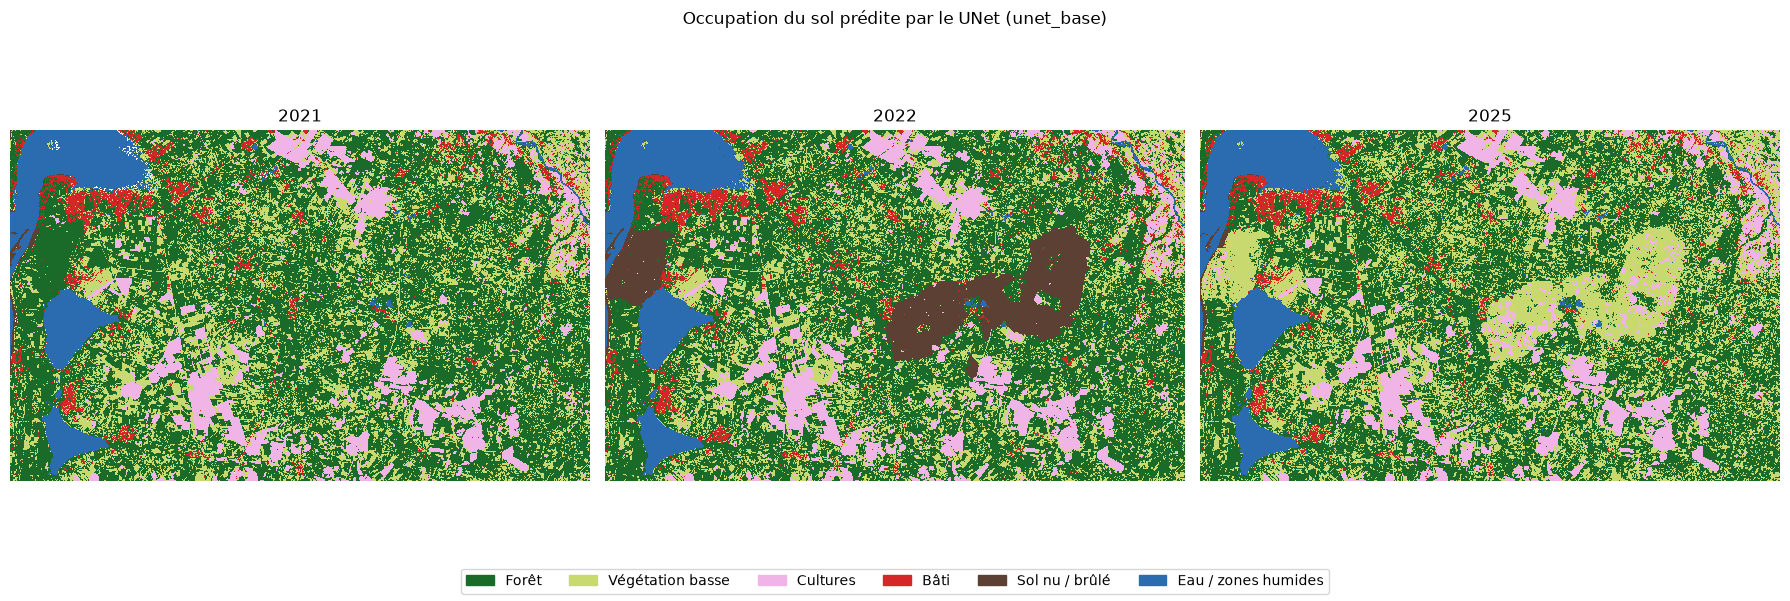

In [5]:
H, W = cartes["2021"].shape
pas_aff = max(1, max(H, W) // 2000)          # sous-échantillonnage pour l'affichage
legende_classes = [Patch(color=CLASSES[k]["couleur"], label=NOMS[k]) for k in range(N_CLASSES)]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, annee in zip(axes, ANNEES):
    ax.imshow(np.ma.masked_equal(cartes[annee][::pas_aff, ::pas_aff], IGNORE),
              cmap=CMAP, vmin=0, vmax=N_CLASSES - 1, interpolation="nearest")
    ax.set_title(annee)
    ax.axis("off")
fig.legend(handles=legende_classes, loc="lower center", ncol=N_CLASSES)
fig.suptitle(f"Occupation du sol prédite par le UNet ({NOM_ESSAI})")
plt.tight_layout(rect=(0, 0.06, 1, 0.97))
plt.savefig(FIG_DIR / f"occupation_3_annees_{NOM_ESSAI}.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Contrôle : carte 2021 prédite contre WorldCover 2021


In [6]:
wc = rioxarray.open_rasterio(DATA_DIR / "worldcover_2021.tif").squeeze("band", drop=True).values
ref = np.full(wc.shape, IGNORE, dtype=np.uint8)
for k, v in CLASSES.items():
    ref[np.isin(wc, v["worldcover"])] = k

ok = (ref != IGNORE) & (cartes["2021"] != IGNORE)
accord = (ref[ok] == cartes["2021"][ok]).mean()
print(f"Accord UNet 2021 / WorldCover 2021 sur toute la zone : {accord * 100:.1f} %")

Accord UNet 2021 / WorldCover 2021 sur toute la zone : 89.1 %


## 6. Indice spectral indépendant : le dNBR


Surface avec dNBR > 0.27 : 86,726 ha


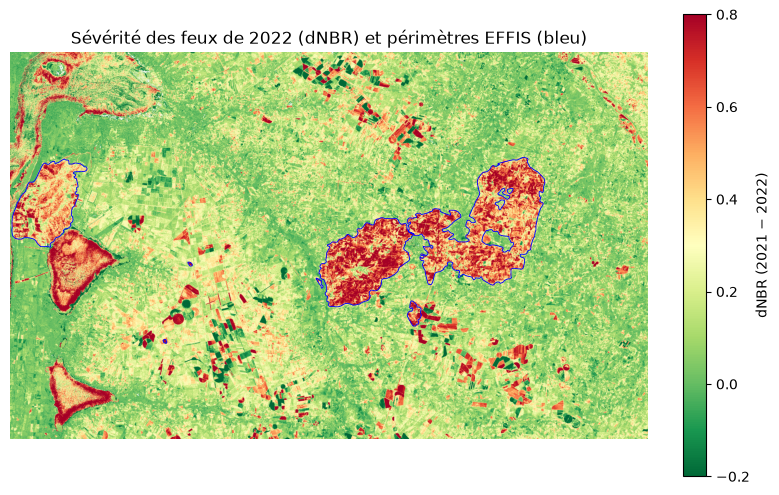

In [7]:
BANDES = CONFIG["bandes"]
i_pir, i_swir2 = BANDES.index("B08"), BANDES.index("B12")


def nbr(annee):
    v = sources[annee].values.astype(np.float32)
    pir, swir2 = v[i_pir], v[i_swir2]
    with np.errstate(divide="ignore", invalid="ignore"):
        r = (pir - swir2) / (pir + swir2)
    r[(v == 0).all(axis=0)] = np.nan
    return r


dnbr = nbr("2021") - nbr("2022")
brule = dnbr > SEUIL_DNBR

# Nettoyage : on retire les groupes de pixels brûlés trop petits pour être un vrai feu
etiq, n = ndimage.label(brule, structure=np.ones((3, 3)))
tailles = np.bincount(etiq.ravel()) * HA_PAR_PIXEL
garder = tailles >= SURFACE_MIN_BRULE_HA
garder[0] = False
brule = garder[etiq]
print(f"Surface avec dNBR > {SEUIL_DNBR} : {brule.sum() * HA_PAR_PIXEL:,.0f} ha")

feux_effis = rioxarray.open_rasterio(DATA_DIR / "feux_effis_2022.tif").squeeze("band", drop=True).values == 1
perte_hansen = rioxarray.open_rasterio(DATA_DIR / "hansen_perte_annee.tif").squeeze("band", drop=True).values

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(dnbr[::pas_aff, ::pas_aff], cmap="RdYlGn_r", vmin=-0.2, vmax=0.8)
ax.contour(feux_effis[::pas_aff, ::pas_aff], levels=[0.5], colors="blue", linewidths=0.6)
plt.colorbar(im, ax=ax, fraction=0.035, label="dNBR (2021 − 2022)")
ax.set_title("Sévérité des feux de 2022 (dNBR) et périmètres EFFIS (bleu)")
ax.axis("off")
plt.savefig(FIG_DIR / "dnbr_2021_2022.png", dpi=200, bbox_inches="tight")
plt.show()

## 6 bis. Validation indépendante de la classe « Sol nu / brûlé » par le dNBR


In [8]:
P = CONFIG["taille_patch"]
zone_test = np.zeros(cartes["2021"].shape, dtype=bool)
for i, j in np.load(DATA_DIR / "patchs_test.npz")["positions"]:
    zone_test[i*P:(i+1)*P, j*P:(j+1)*P] = True


def ha(m):
    return m.sum() * HA_PAR_PIXEL


valide_dnbr = ~np.isnan(dnbr) & (cartes["2021"] != IGNORE) & (cartes["2022"] != IGNORE)
foret_21 = (cartes["2021"] == FORET) & valide_dnbr
pred_brule_22 = cartes["2022"] == BRULE

# Découpage dans / hors des périmètres EFFIS : hors périmètres, un dNBR élevé signale surtout
# autre chose qu'un feu (coupe rase, sécheresse de 2022, décalage de saison entre les deux fenêtres)
zones = {
    "toute la zone": np.ones_like(zone_test),
    "zone de test": zone_test,
    "zone de test, dans EFFIS": zone_test & feux_effis,
    "zone de test, hors EFFIS": zone_test & ~feux_effis,
}
validation = {}
for nom, zone in zones.items():
    f = foret_21 & zone
    vp = ha(f & brule & pred_brule_22)
    validation[nom] = {
        "forêt 2021 brûlée selon dNBR (ha)": ha(f & brule),
        "forêt 2021 prédite brûlée en 2022 (ha)": ha(f & pred_brule_22),
        "rappel dNBR (%)": vp / max(ha(f & brule), 1e-9) * 100,
        "précision dNBR (%)": vp / max(ha(f & pred_brule_22), 1e-9) * 100,
    }
validation = pd.DataFrame(validation).round(1)
display(validation)

dnbr_effis = dnbr[feux_effis & ~np.isnan(dnbr)]
qualite_effis = {
    "surface des périmètres EFFIS (ha)": ha(feux_effis),
    "part avec dNBR > 0,27 (%)": (dnbr_effis > SEUIL_DNBR).mean() * 100,
    "part avec dNBR < 0,10, îlots non brûlés probables (%)": (dnbr_effis < SEUIL_NON_BRULE).mean() * 100,
    "part de la surface dNBR > 0,27 située dans un périmètre EFFIS (%)": ha(brule & feux_effis) / max(ha(brule), 1e-9) * 100,
    "forêt 2021 hors EFFIS avec dNBR > 0,27 (ha)": ha(foret_21 & brule & ~feux_effis),
    "  dont coupes Hansen 2021-2022 (%)": ha(foret_21 & brule & ~feux_effis & np.isin(perte_hansen, [21, 22]))
                                          / max(ha(foret_21 & brule & ~feux_effis), 1e-9) * 100,
}
pd.Series(qualite_effis).round(1).to_frame("valeur")

,toute la zone,zone de test,"zone de test, dans EFFIS","zone de test, hors EFFIS"
forêt 2021 brûlée selon dNBR (ha),26188.4,5619.3,4064.1,1555.2
forêt 2021 prédite brûlée en 2022 (ha),19517.3,4607.8,4423.8,184.0
rappel dNBR (%),64.8,73.7,99.8,5.6
précision dNBR (%),87.0,89.9,91.7,47.1


,valeur
surface des périmètres EFFIS (ha),26866.9
"part avec dNBR > 0,27 (%)",87.8
"part avec dNBR < 0,10, îlots non brûlés probables (%)",2.6
"part de la surface dNBR > 0,27 située dans un périmètre EFFIS (%)",27.1
"forêt 2021 hors EFFIS avec dNBR > 0,27 (ha)",9431.4
dont coupes Hansen 2021-2022 (%),23.7


## 7. Indicateur 1 : surfaces par classe et par année

In [9]:
valide = np.all([cartes[a] != IGNORE for a in ANNEES], axis=0)
print(f"Pixels valides les 3 années : {valide.mean() * 100:.1f} % de la zone")

surfaces = pd.DataFrame({
    annee: np.bincount(cartes[annee][valide], minlength=N_CLASSES) * HA_PAR_PIXEL for annee in ANNEES
}, index=NOMS)
parts = (surfaces / surfaces.sum() * 100).round(1)
evolution = surfaces.assign(
    **{"Δ 2021→2022 (ha)": surfaces["2022"] - surfaces["2021"],
       "Δ 2022→2025 (ha)": surfaces["2025"] - surfaces["2022"]}
).round(0)
display(evolution)
display(parts.add_suffix(" (%)"))

Pixels valides les 3 années : 99.8 % de la zone


,2021,2022,2025,Δ 2021→2022 (ha),Δ 2022→2025 (ha)
Forêt,196335.0,177479.0,165028.0,-18856.0,-12451.0
Végétation basse,87567.0,76342.0,116883.0,-11225.0,40541.0
Cultures,34269.0,36107.0,35702.0,1837.0,-405.0
Bâti,12495.0,13898.0,12668.0,1403.0,-1230.0
Sol nu / brûlé,1230.0,28151.0,1150.0,26921.0,-27002.0
Eau / zones humides,24400.0,24320.0,24867.0,-80.0,547.0


,2021 (%),2022 (%),2025 (%)
Forêt,55.1,49.8,46.3
Végétation basse,24.6,21.4,32.8
Cultures,9.6,10.1,10.0
Bâti,3.5,3.9,3.6
Sol nu / brûlé,0.3,7.9,0.3
Eau / zones humides,6.8,6.8,7.0


## 8. Indicateur 2 : matrice de transition 2021 → 2022


In [10]:
def transitions(a, b):
    m = valide
    t = np.bincount(N_CLASSES * cartes[a][m] + cartes[b][m], minlength=N_CLASSES**2).reshape(N_CLASSES, N_CLASSES)
    return pd.DataFrame(t * HA_PAR_PIXEL, index=[f"{n} ({a})" for n in NOMS],
                        columns=[f"{n} ({b})" for n in NOMS]).round(0)


display(transitions("2021", "2022"))
display(transitions("2022", "2025"))

,Forêt (2022),Végétation basse (2022),Cultures (2022),Bâti (2022),Sol nu / brûlé (2022),Eau / zones humides (2022)
Forêt (2021),166749.0,9106.0,358.0,496.0,19517.0,107.0
Végétation basse (2021),10172.0,63418.0,5327.0,1550.0,7028.0,73.0
Cultures (2021),249.0,3241.0,30336.0,77.0,353.0,14.0
Bâti (2021),231.0,376.0,60.0,11733.0,76.0,19.0
Sol nu / brûlé (2021),0.0,48.0,15.0,24.0,1060.0,83.0
Eau / zones humides (2021),78.0,153.0,10.0,18.0,117.0,24023.0


,Forêt (2025),Végétation basse (2025),Cultures (2025),Bâti (2025),Sol nu / brûlé (2025),Eau / zones humides (2025)
Forêt (2022),149868.0,25725.0,1062.0,499.0,7.0,318.0
Végétation basse (2022),13196.0,59119.0,3185.0,578.0,70.0,193.0
Cultures (2022),361.0,8094.0,27545.0,88.0,5.0,14.0
Bâti (2022),206.0,2284.0,104.0,11265.0,21.0,18.0
Sol nu / brûlé (2022),1321.0,21598.0,3795.0,221.0,953.0,263.0
Eau / zones humides (2022),75.0,63.0,10.0,17.0,94.0,24061.0


## 9. Indicateur 3 : forêt perdue et reprise de la végétation


In [11]:
f21, f22, f25 = (cartes[a] == FORET for a in ANNEES)
foret_2021 = f21 & valide
perdue = foret_2021 & ~f22
perdue_feu = perdue & brule
perdue_autre = perdue & ~brule

devenir = {
    "Forêt en 2025": perdue & f25,
    "Végétation basse en 2025": perdue & (cartes["2025"] == VEG_BASSE),
    "Sol nu / brûlé en 2025": perdue & (cartes["2025"] == BRULE),
    "Autre (cultures, bâti, eau) en 2025": perdue & ~f25 & ~np.isin(cartes["2025"], [VEG_BASSE, BRULE]),
}

indicateurs = {
    "foret_2021_ha": ha(foret_2021),
    "foret_2022_ha": ha(f22 & valide),
    "foret_2025_ha": ha(f25 & valide),
    "foret_perdue_2022_ha": ha(perdue),
    "foret_devenue_brulee_2022_ha": ha(foret_2021 & (cartes["2022"] == BRULE)),
    "taux_perte_2021_2022_pct": ha(perdue) / max(ha(foret_2021), 1e-9) * 100,
    "perte_attribuable_feux_pct": ha(perdue_feu) / max(ha(perdue), 1e-9) * 100,
    "zones_brulees_dnbr_detectees_par_unet_pct": ha(perdue_feu) / max(ha(brule & foret_2021), 1e-9) * 100,
    "nouvelle_perte_2022_2025_ha": ha(f21 & f22 & ~f25 & valide),
    "nouvelle_perte_2022_2025_dans_zones_brulees_dnbr_ha": ha(f21 & f22 & ~f25 & valide & brule),
    # Validation indépendante : la perte 2022 -> 2025 correspond-elle à des pertes Hansen de 2023-2024 ?
    "nouvelle_perte_2022_2025_confirmee_par_hansen_2023_2024_pct":
        ha(f21 & f22 & ~f25 & valide & np.isin(perte_hansen, [23, 24])) / max(ha(f21 & f22 & ~f25 & valide), 1e-9) * 100,
}
for nom, m in devenir.items():
    indicateurs[f"devenir_2025 : {nom} (% de la forêt perdue)"] = ha(m) / max(ha(perdue), 1e-9) * 100
for nom, m in devenir.items():
    indicateurs[f"devenir_2025 des pertes dues aux feux : {nom} (%)"] = ha(m & brule) / max(ha(perdue_feu), 1e-9) * 100

pd.Series(indicateurs).round(1).to_frame("valeur")

,valeur
foret_2021_ha,196334.6
foret_2022_ha,177478.7
foret_2025_ha,165027.6
foret_perdue_2022_ha,29585.6
foret_devenue_brulee_2022_ha,19517.3
taux_perte_2021_2022_pct,15.1
perte_attribuable_feux_pct,71.9
zones_brulees_dnbr_detectees_par_unet_pct,81.3
nouvelle_perte_2022_2025_ha,22303.4
nouvelle_perte_2022_2025_dans_zones_brulees_dnbr_ha,2133.6


## 10. Indicateur 4 : fragmentation du massif forestier


In [12]:
def fragmentation(masque):
    etiq, n = ndimage.label(masque, structure=np.ones((3, 3)))
    if n == 0:
        return {"n_taches": 0, "surface_moyenne_ha": 0, "plus_grande_tache_pct": 0, "taches_<_1ha_pct_surface": 0}
    tailles = np.bincount(etiq.ravel())[1:] * HA_PAR_PIXEL
    return {
        "n_taches": int(n),
        "surface_moyenne_ha": tailles.mean(),
        "plus_grande_tache_pct": tailles.max() / tailles.sum() * 100,
        "taches_<_1ha_pct_surface": tailles[tailles < 1].sum() / tailles.sum() * 100,
    }

frag = pd.DataFrame({a: fragmentation((cartes[a] == FORET) & valide) for a in ANNEES}).round(2)
frag

,2021,2022,2025
n_taches,8347.00,8281.00,10355.00
surface_moyenne_ha,23.52,21.43,15.94
plus_grande_tache_pct,55.12,53.11,28.50
taches_<_1ha_pct_surface,0.64,0.67,0.98


## 11. Carte des changements


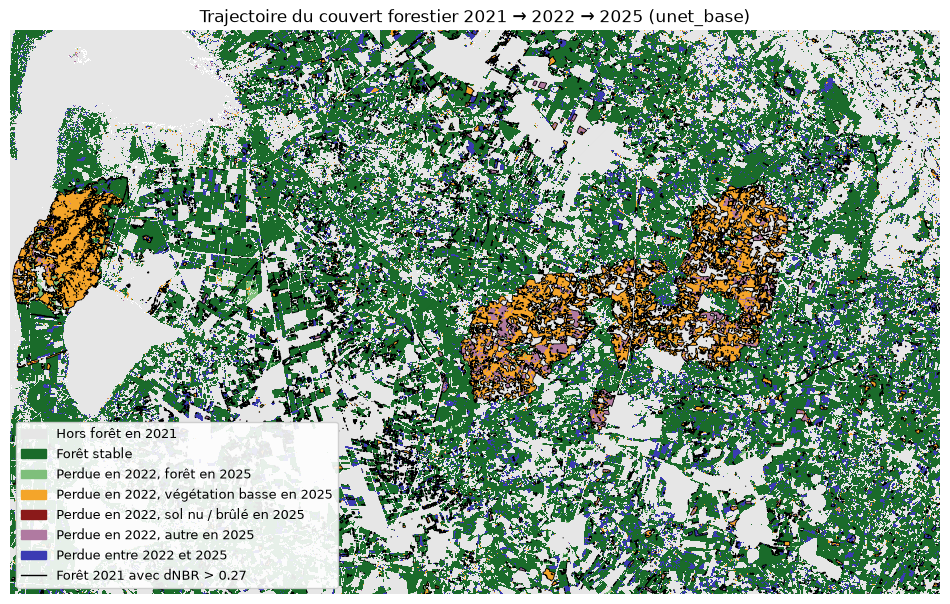

In [13]:
TRAJ = [
    ("Hors forêt en 2021",                               "#e6e6e6"),
    ("Forêt stable",                                     "#1a6b2a"),
    ("Perdue en 2022, forêt en 2025",                    "#7fbf7b"),
    ("Perdue en 2022, végétation basse en 2025",         "#f4a52a"),
    ("Perdue en 2022, sol nu / brûlé en 2025",           "#8b1a1a"),
    ("Perdue en 2022, autre en 2025",                    "#b07aa1"),
    ("Perdue entre 2022 et 2025",                        "#3b3bb3"),
]
traj = np.zeros(cartes["2021"].shape, dtype=np.uint8)
traj[foret_2021 & f22 & f25] = 1
for k, m in enumerate(devenir.values(), start=2):
    traj[m] = k
traj[foret_2021 & f22 & ~f25] = 6
traj[~valide] = IGNORE

ref = sources["2021"].isel(band=0)
out = ref.copy(data=traj)
out.attrs.pop("long_name", None)
out.rio.write_nodata(IGNORE).rio.to_raster(DATA_DIR / f"trajectoires_foret_{NOM_ESSAI}.tif", compress="deflate")

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(np.ma.masked_equal(traj[::pas_aff, ::pas_aff], IGNORE),
          cmap=ListedColormap([c for _, c in TRAJ]), vmin=0, vmax=len(TRAJ) - 1, interpolation="nearest")
ax.contour((brule & foret_2021)[::pas_aff, ::pas_aff].astype(float), levels=[0.5], colors="black", linewidths=0.6)
handles = [Patch(color=c, label=n) for n, c in TRAJ] + [plt.Line2D([], [], color="black", lw=1, label=f"Forêt 2021 avec dNBR > {SEUIL_DNBR}")]
ax.legend(handles=handles, loc="lower left", fontsize=9, framealpha=0.9)
ax.set_title(f"Trajectoire du couvert forestier 2021 → 2022 → 2025 ({NOM_ESSAI})")
ax.axis("off")
plt.savefig(FIG_DIR / f"carte_trajectoires_foret_{NOM_ESSAI}.png", dpi=200, bbox_inches="tight")
plt.show()

## 12. Graphiques de synthèse

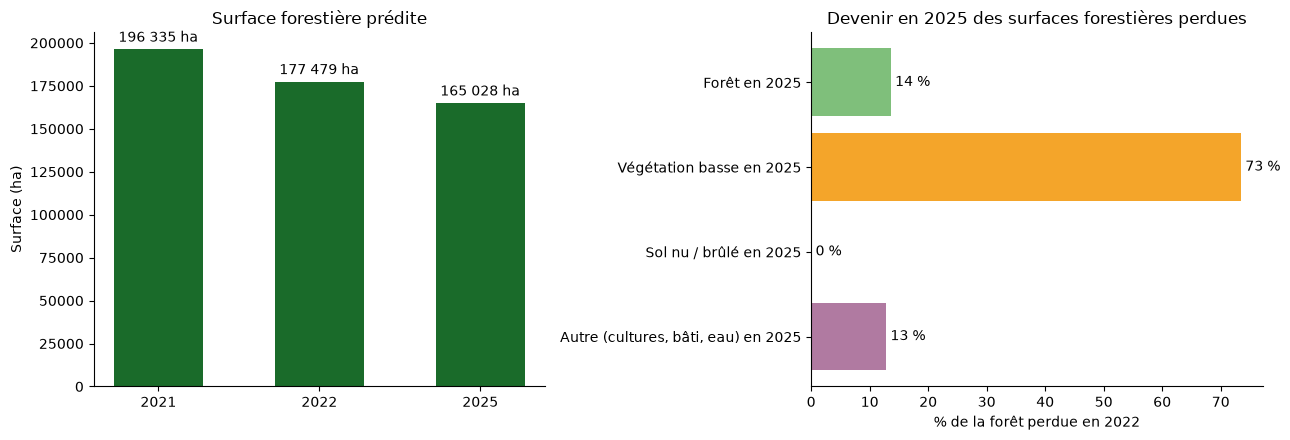

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Surface forestière par année
vals = [indicateurs[f"foret_{a}_ha"] for a in ANNEES]
barres = axes[0].bar(ANNEES, vals, color="#1a6b2a", width=0.55)
axes[0].bar_label(barres, labels=[f"{v:,.0f} ha".replace(",", " ") for v in vals], padding=3)
axes[0].set_ylabel("Surface (ha)")
axes[0].set_title("Surface forestière prédite")

# Devenir en 2025 de la forêt perdue en 2022
noms_dev = list(devenir)
parts_dev = [indicateurs[f"devenir_2025 : {n} (% de la forêt perdue)"] for n in noms_dev]
couleurs_dev = [c for _, c in TRAJ[2:6]]
barres = axes[1].barh(noms_dev, parts_dev, color=couleurs_dev)
axes[1].bar_label(barres, labels=[f"{p:.0f} %" for p in parts_dev], padding=3)
axes[1].invert_yaxis()
axes[1].set_xlabel("% de la forêt perdue en 2022")
axes[1].set_title("Devenir en 2025 des surfaces forestières perdues")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / f"synthese_indicateurs_{NOM_ESSAI}.png", dpi=200, bbox_inches="tight")
plt.show()

## 13. Sauvegarde des indicateurs

In [15]:
sortie = {
    "modele": NOM_ESSAI,
    "seuil_dnbr": SEUIL_DNBR,
    "accord_2021_worldcover_pct": float(accord * 100),
    "validation_dnbr": validation.to_dict(),
    "qualite_perimetres_effis": {k: float(v) for k, v in qualite_effis.items()},
    "indicateurs": {k: float(v) for k, v in indicateurs.items()},
    "fragmentation": frag.to_dict(),
}
with open(DATA_DIR / f"indicateurs_{NOM_ESSAI}.json", "w") as f:
    json.dump(sortie, f, indent=2, ensure_ascii=False, default=float)
evolution.to_csv(DATA_DIR / f"surfaces_par_classe_{NOM_ESSAI}.csv")
print(f"-> data/indicateurs_{NOM_ESSAI}.json, data/surfaces_par_classe_{NOM_ESSAI}.csv")

-> data/indicateurs_unet_base.json, data/surfaces_par_classe_unet_base.csv


## 14. Comparaison des indicateurs entre essais


In [16]:
lignes = {}
for f in sorted(DATA_DIR.glob("indicateurs_*.json")):
    r = json.load(open(f))
    ligne = {"accord WorldCover 2021 (%)": r["accord_2021_worldcover_pct"]}
    ligne.update({f"{k} ({z})": v for z, d in r["validation_dnbr"].items() for k, v in d.items() if "%" in k})
    ligne.update(r["indicateurs"])
    lignes[r["modele"]] = ligne
pd.DataFrame(lignes).round(1)

,unet_2021_seul,unet_base,unet_sans_poids
accord WorldCover 2021 (%),88.0,89.1,89.8
rappel dNBR (%) (toute la zone),0.1,64.8,62.3
précision dNBR (%) (toute la zone),91.3,87.0,87.6
rappel dNBR (%) (zone de test),0.0,73.7,71.6
précision dNBR (%) (zone de test),23.3,89.9,90.6
"rappel dNBR (%) (zone de test, dans EFFIS)",0.0,99.8,99.5
"précision dNBR (%) (zone de test, dans EFFIS)",0.0,91.7,91.9
"rappel dNBR (%) (zone de test, hors EFFIS)",0.0,5.6,4.6
"précision dNBR (%) (zone de test, hors EFFIS)",23.3,47.1,52.0
foret_2021_ha,199943.1,196334.6,208182.1
